Accuracy: 0.5688073394495413
              precision    recall  f1-score   support

           0       0.56      0.53      0.55       107
           1       0.57      0.60      0.59       111

    accuracy                           0.57       218
   macro avg       0.57      0.57      0.57       218
weighted avg       0.57      0.57      0.57       218

[[57 50]
 [44 67]]


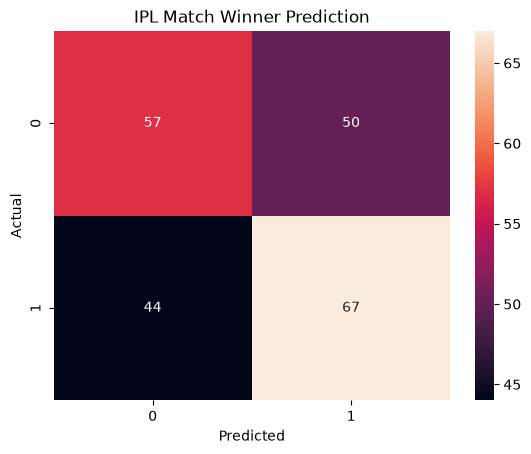

venue_encoded       0.206407
toss_encoded        0.201357
decision_encoded    0.201107
team1_encoded       0.198321
team2_encoded       0.192809
dtype: float32


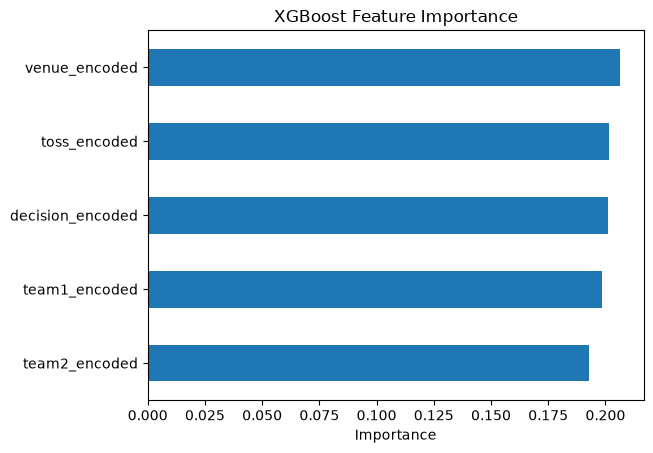

In [29]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

matches = pd.read_csv(
    "../data/processed/matches_cleaned.csv"
)
matches.head()

matches.columns.tolist()
matches = matches.dropna(subset=["winner"])
matches["winner"].isna().sum()
ml_data = matches[
    [
        "team1",
        "team2",
        "toss_winner",
        "toss_decision",
        "venue",
        "winner"
    ]
].copy()

ml_data.head()

ml_data["team1_won"] = (
    ml_data["winner"] == ml_data["team1"]
).astype(int)
ml_data[["team1", "team2", "winner", "team1_won"]].head(10)

le_team1 = LabelEncoder()
le_team2 = LabelEncoder()
le_toss = LabelEncoder()
le_venue = LabelEncoder()
le_decision = LabelEncoder()

ml_data["team1_encoded"] = le_team1.fit_transform(
    ml_data["team1"]
)

ml_data["team2_encoded"] = le_team2.fit_transform(
    ml_data["team2"]
)

ml_data["toss_encoded"] = le_toss.fit_transform(
    ml_data["toss_winner"]
)

ml_data["venue_encoded"] = le_venue.fit_transform(
    ml_data["venue"]
)

ml_data["decision_encoded"] = le_decision.fit_transform(
    ml_data["toss_decision"]
)
X = ml_data[
    [
        "team1_encoded",
        "team2_encoded",
        "toss_encoded",
        "venue_encoded",
        "decision_encoded"
    ]
]
y = ml_data["team1_won"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print(
    classification_report(
        y_test,
        y_pred
    )
)

cm = confusion_matrix(y_test, y_pred)

print(cm)

import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("IPL Match Winner Prediction")
plt.show()

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

importance.sort_values().plot(
    kind="barh"
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.show()


import joblib
joblib.dump(
    model,
    "../ai/ipl_match_winner_model.pkl"
)

results = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred
})
results.head()

results.to_csv(
    "../ai/model_results.csv",
    index=False
)
results.to_csv("../ai/model_results.csv")